In [1]:
import torch
from torch.utils.data import Dataset

class ABSADataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len=128):
        self.df = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.loc[idx]

        sentence = row["Sentence"]
        aspect = row["Aspect Term"]
        label = LABEL_MAP[row["polarity"]]

        encoding = self.tokenizer(
            sentence,
            aspect,
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )

        item = {k: v.squeeze(0) for k, v in encoding.items()}
        item["labels"] = torch.tensor(label, dtype=torch.long)

        return item


In [ ]:
import torch
import pandas as pd
import os
from torch.utils.data import DataLoader
from torch.optim import AdamW

from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score



MODEL_NAME = "bert-base-uncased"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 10
LR = 2e-5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_SAVE_PATH = "bert_absa_finetuned_model"

LABEL_MAP = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
    "conflict": 3
}

print(f"Using device: {DEVICE}")


df = pd.read_csv(
    r"D:\Sem6\NLP\absa-nlp\data\raw\Laptop_Train_v2.csv"
)

print(f"Total samples: {len(df)}")
print(f"Label distribution:\n{df['polarity'].value_counts()}")

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["polarity"]
)

print(f"Train samples: {len(train_df)}, Val samples: {len(val_df)}")

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

train_dataset = ABSADataset(train_df, tokenizer)
val_dataset = ABSADataset(val_df, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)


if os.path.exists(MODEL_SAVE_PATH) and os.path.exists(os.path.join(MODEL_SAVE_PATH, "pytorch_model.bin")):
    print(f"\n{'='*60}")
    print(f"Model weights found at '{MODEL_SAVE_PATH}'")
    print("Loading pre-trained model...")
    print(f"{'='*60}\n")
    
    model = BertForSequenceClassification.from_pretrained(MODEL_SAVE_PATH)
    model.to(DEVICE)
    
    print("Evaluating loaded model...")
    model.eval()
    preds, labels = [], []
    
    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            outputs = model(**batch)
            logits = outputs.logits
            preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
            labels.extend(batch["labels"].cpu().numpy())
    
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")
    print(f"Loaded Model - Val Acc: {acc:.4f} | Val F1: {f1:.4f}\n")
    
else:
    print(f"\n{'='*60}")
    print("No existing model found. Starting training...")
    print(f"{'='*60}\n")
    
    # Model
    model = BertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=4
    )
    model.to(DEVICE)


    # Optimizer & Scheduler
    optimizer = AdamW(model.parameters(), lr=LR)

    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=0,
        num_training_steps=total_steps
    )


    # Training Loop
    def train_epoch(model, loader):
        model.train()
        total_loss = 0

        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = model(**batch)
            loss = outputs.loss

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

            total_loss += loss.item()

        return total_loss / len(loader)


    # Evaluation
    def evaluate(model, loader):
        model.eval()
        preds, labels = [], []

        with torch.no_grad():
            for batch in loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                outputs = model(**batch)

                logits = outputs.logits
                preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
                labels.extend(batch["labels"].cpu().numpy())

        acc = accuracy_score(labels, preds)
        f1 = f1_score(labels, preds, average="macro")
        return acc, f1


    # Run Training
    best_f1 = 0.0
    for epoch in range(EPOCHS):
        loss = train_epoch(model, train_loader)
        acc, f1 = evaluate(model, val_loader)

        print(f"Epoch {epoch+1}/{EPOCHS}")
        print(f"Loss: {loss:.4f} | Val Acc: {acc:.4f} | Val F1: {f1:.4f}")
        
        # Save best model
        if f1 > best_f1:
            best_f1 = f1
            print(f"  → New best F1! Saving checkpoint...")


    # Save the final model
    print(f"\n{'='*60}")
    print(f"Training complete! Saving model to '{MODEL_SAVE_PATH}'")
    print(f"{'='*60}\n")
    
    model.save_pretrained(MODEL_SAVE_PATH)
    tokenizer.save_pretrained(MODEL_SAVE_PATH)
    
    print(f"Model saved successfully!")
    print(f"Best Validation F1: {best_f1:.4f}")


d:\System\Conda\envs\absa\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda
Total samples: 2358
Label distribution:
polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64
Train samples: 1886, Val samples: 472

No existing model found. Starting training...



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
Loss: 1.1266 | Val Acc: 0.6928 | Val F1: 0.3918
  → New best F1! Saving checkpoint...
Epoch 2/10
Loss: 0.7785 | Val Acc: 0.7331 | Val F1: 0.4911
  → New best F1! Saving checkpoint...
Epoch 3/10
Loss: 0.5917 | Val Acc: 0.7415 | Val F1: 0.5293
  → New best F1! Saving checkpoint...
Epoch 4/10
Loss: 0.4839 | Val Acc: 0.7627 | Val F1: 0.5550
  → New best F1! Saving checkpoint...
Epoch 5/10
Loss: 0.3931 | Val Acc: 0.7479 | Val F1: 0.5424
Epoch 6/10
Loss: 0.3133 | Val Acc: 0.7691 | Val F1: 0.5519
Epoch 7/10
Loss: 0.2539 | Val Acc: 0.7500 | Val F1: 0.5470
Epoch 8/10
Loss: 0.2085 | Val Acc: 0.7754 | Val F1: 0.5631
  → New best F1! Saving checkpoint...
Epoch 9/10
Loss: 0.1796 | Val Acc: 0.7754 | Val F1: 0.5649
  → New best F1! Saving checkpoint...
Epoch 10/10
Loss: 0.1590 | Val Acc: 0.7754 | Val F1: 0.5605

Training complete! Saving model to 'bert_absa_finetuned_model'

Model saved successfully!
Best Validation F1: 0.5649



COMPREHENSIVE MODEL EVALUATION

Loading model from 'bert_absa_finetuned_model'...
Model loaded successfully!

Running predictions on validation set...

EVALUATION METRICS
Accuracy:           0.7754
F1-Score (Macro):   0.5605
F1-Score (Weighted):0.7681
Precision (Macro):  0.5564
Recall (Macro):     0.5648

CLASSIFICATION REPORT:
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.81      0.81      0.81       173
     neutral       0.58      0.58      0.58        92
    positive       0.84      0.87      0.85       198
    conflict       0.00      0.00      0.00         9

    accuracy                           0.78       472
   macro avg       0.56      0.56      0.56       472
weighted avg       0.76      0.78      0.77       472


CONFUSION MATRIX
[[140  20  12   1]
 [ 20  53  19   0]
 [  9  16 173   0]
 [  3   3   3   0]]


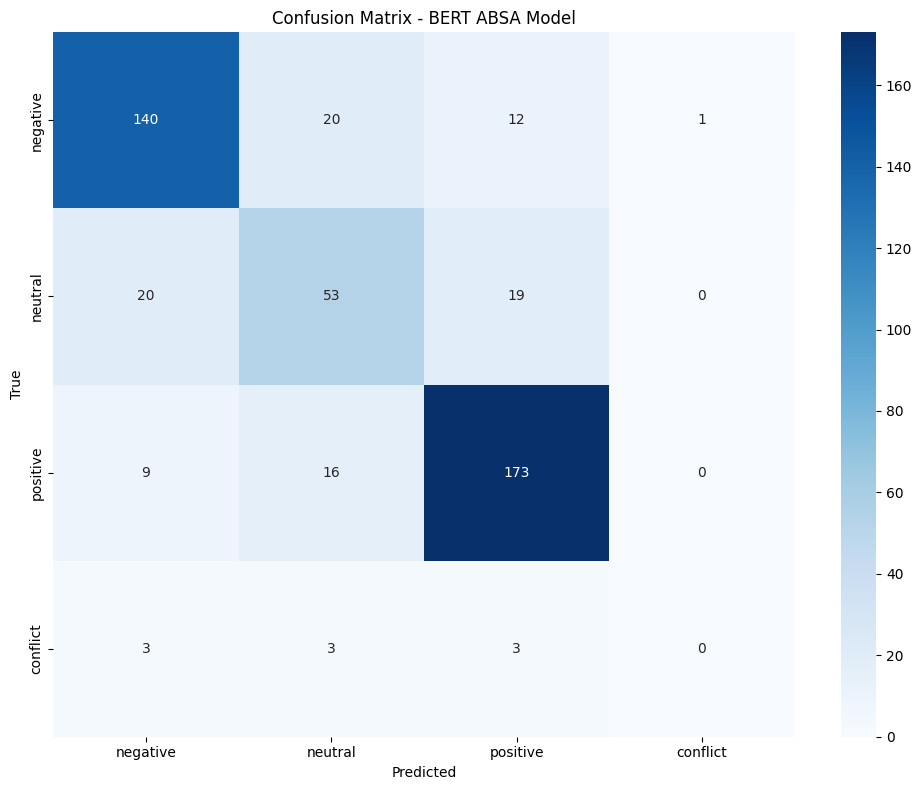


PER-CLASS METRICS
Negative     - Precision: 0.8140 | Recall: 0.8092 | F1: 0.8116 | Support: 173
Neutral      - Precision: 0.5761 | Recall: 0.5761 | F1: 0.5761 | Support: 92
Positive     - Precision: 0.8357 | Recall: 0.8737 | F1: 0.8543 | Support: 198
Conflict     - Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 9


EXAMPLE PREDICTIONS

Sentence: I charge it at night and skip taking the cord with me because of the good battery life.
Aspect:   battery life
Predicted: POSITIVE (confidence: 0.9915)
All probabilities: {'negative': 0.0014485296560451388, 'neutral': 0.002664316212758422, 'positive': 0.9914980530738831, 'conflict': 0.004389077425003052}
------------------------------------------------------------

Sentence: The screen resolution is terrible and colors look washed out.
Aspect:   screen resolution
Predicted: NEGATIVE (confidence: 0.9857)
All probabilities: {'negative': 0.9856560230255127, 'neutral': 0.007168591022491455, 'positive': 0.0013982560485601425, 'conflict'

In [ ]:
import torch
import numpy as np
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt


# Config
MODEL_PATH = "bert_absa_finetuned_model"   # Must match the saved model path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Label mapping (MUST match training)
LABEL_MAP = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
    "conflict": 3
}

ID2LABEL = {
    0: "negative",
    1: "neutral",
    2: "positive",
    3: "conflict"
}

print(f"\n{'='*60}")
print("COMPREHENSIVE MODEL EVALUATION")
print(f"{'='*60}\n")

# Load model & tokenizer
print(f"Loading model from '{MODEL_PATH}'...")
tokenizer = BertTokenizer.from_pretrained(MODEL_PATH)
model = BertForSequenceClassification.from_pretrained(MODEL_PATH)
model.to(DEVICE)
model.eval()
print("Model loaded successfully!\n")

# Get predictions on validation set
print("Running predictions on validation set...")
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        outputs = model(**batch)
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        labels = batch["labels"].cpu().numpy()
        
        all_preds.extend(preds)
        all_labels.extend(labels)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
f1_macro = f1_score(all_labels, all_preds, average="macro")
f1_weighted = f1_score(all_labels, all_preds, average="weighted")
precision_macro = precision_score(all_labels, all_preds, average="macro")
recall_macro = recall_score(all_labels, all_preds, average="macro")

print(f"\n{'='*60}")
print("EVALUATION METRICS")
print(f"{'='*60}")
print(f"Accuracy:           {accuracy:.4f}")
print(f"F1-Score (Macro):   {f1_macro:.4f}")
print(f"F1-Score (Weighted):{f1_weighted:.4f}")
print(f"Precision (Macro):  {precision_macro:.4f}")
print(f"Recall (Macro):     {recall_macro:.4f}")
print(f"{'='*60}\n")

# Detailed classification report
print("CLASSIFICATION REPORT:")
print(f"{'-'*60}")
target_names = [ID2LABEL[i] for i in range(len(ID2LABEL))]
print(classification_report(all_labels, all_preds, target_names=target_names))

# Confusion Matrix
print(f"\n{'='*60}")
print("CONFUSION MATRIX")
print(f"{'='*60}")
cm = confusion_matrix(all_labels, all_preds)
print(cm)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, 
            yticklabels=target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - BERT ABSA Model')
plt.tight_layout()
plt.show()

# Per-class metrics
print(f"\n{'='*60}")
print("PER-CLASS METRICS")
print(f"{'='*60}")
for i, label_name in enumerate(target_names):
    precision = precision_score(all_labels, all_preds, labels=[i], average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, labels=[i], average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, labels=[i], average='macro', zero_division=0)
    support = np.sum(all_labels == i)
    
    print(f"{label_name.capitalize():12} - Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f} | Support: {support}")

print(f"{'='*60}\n")


# Prediction function for inference
def predict_aspect_sentiment(sentence, aspect):
    """
    Predict sentiment for a given sentence-aspect pair
    """
    inputs = tokenizer(
        sentence,
        aspect,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=1)[0]
        pred_id = torch.argmax(logits, dim=1).item()

    return {
        "sentiment": ID2LABEL[pred_id],
        "confidence": probs[pred_id].item(),
        "all_probabilities": {ID2LABEL[i]: probs[i].item() for i in range(len(ID2LABEL))}
    }


# Example test cases
print("EXAMPLE PREDICTIONS")


test_cases = [
    ("I charge it at night and skip taking the cord with me because of the good battery life.", "battery life"),
    ("The screen resolution is terrible and colors look washed out.", "screen resolution"),
    ("The keyboard is okay but nothing special.", "keyboard"),
]

for sentence, aspect in test_cases:
    result = predict_aspect_sentiment(sentence, aspect)
    print(f"Sentence: {sentence}")
    print(f"Aspect:   {aspect}")
    print(f"Predicted: {result['sentiment'].upper()} (confidence: {result['confidence']:.4f})")
    print(f"All probabilities: {result['all_probabilities']}")
    print(f"{'-'*60}\n")
